
Label: DIED

Classifier: Logistic_Regression   
Average Metrics over 20 10-fold cross-validations (mean±std):
AUROC          56.8%±2.6%
Sensitivity    26.1%±5.3%
Specificity    80.1%±1.9%
F1-score       21.0%±4.4%
AUPRC          18.9%±1.8%
dtype: object

Classifier: SVM_(RBF_Kernel)   
Average Metrics over 20 10-fold cross-validations (mean±std):
AUROC          63.2%±2.7%
Sensitivity    61.8%±5.0%
Specificity    59.0%±2.1%
F1-score       29.8%±2.2%
AUPRC          27.2%±4.8%
dtype: object

Classifier: Random_Forest   
Average Metrics over 20 10-fold cross-validations (mean±std):
AUROC          75.2%±1.8%
Sensitivity     2.0%±2.7%
Specificity    99.3%±0.0%
F1-score        3.7%±5.0%
AUPRC          31.1%±2.3%
dtype: object

Classifier: XGBoost   
Average Metrics over 20 10-fold cross-validations (mean±std):
AUROC          66.9%±2.7%
Sensitivity     3.6%±1.9%
Specificity    98.7%±0.6%
F1-score        6.5%±3.3%
AUPRC          26.7%±3.1%
dtype: object


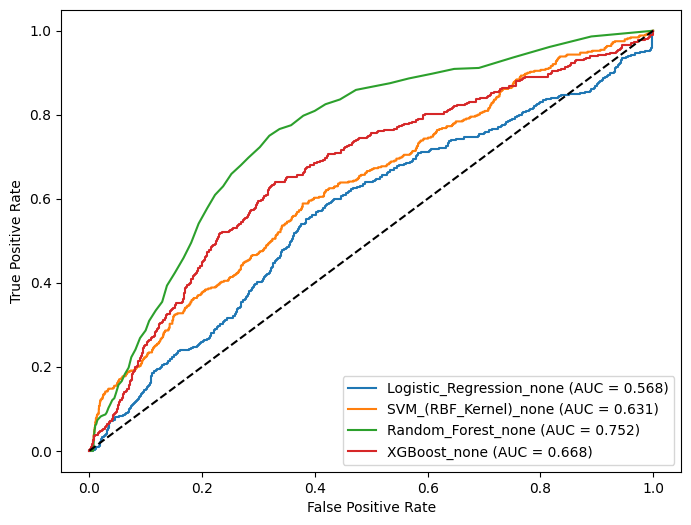

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from classification import *

def main():
    set_seed(42)
    label_name = 'DIED'
    print(f"\nLabel: {label_name}")

    classifiers = {
        'Logistic_Regression': LogisticRegression(max_iter=1000, random_state=42),
        'SVM_(RBF_Kernel)': SVC(kernel='rbf', probability=True, random_state=42),
        'Random_Forest': RandomForestClassifier(random_state=42),
        'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    }

    calibrators = ['none']
    use_pca = False
    n_components = 0.9

    feature_list = ECG_feature_names

    split_method = 'kfold'
    kfold = 10
    num_splits = 200
    use_RFE = False
    RFE_feature_number = 100

    plt.figure(figsize=(8, 6))  # Create a figure for plotting ROC curves

    # Loop over classifiers
    for calibrator in calibrators:
        for clf_name, clf in classifiers.items():
            combined_name = f"{clf_name}_{calibrator}{'_PCA' if use_pca else ''}"

            (
                metrics_list, 
                auroc_list, 
                auprc_list, 
                feature_names,
                all_y_test,   # <--- out-of-fold test labels
                all_y_prob    # <--- out-of-fold predicted probabilities
            ) = train_and_evaluate_classifier(
                clf_name, 
                copy.deepcopy(clf), 
                label_name, 
                calibrator, 
                split_method, 
                kfold, 
                num_splits,
                use_pca, 
                n_components, 
                feature_list, 
                use_RFE, 
                RFE_feature_number
            )

            # Plot a single ROC curve from the accumulated predictions
            fpr, tpr, _ = roc_curve(all_y_test, all_y_prob)
            roc_auc = roc_auc_score(all_y_test, all_y_prob)

            plt.plot(
                fpr, tpr, 
                label=f"{combined_name} (AUC = {roc_auc:.3f})"
            )

    plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.savefig('../figures/roc_curve_E.png', dpi=300)
    plt.show()

main()